# Tutorial 72: WORK IN PROGRESS: Longitudinal Sections

This example demonstrates how to ...

# SIR 3S Installation

In [1]:
SIR3S_SIRGRAF_DIR = r"C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2" #change to local path

# Imports

In [2]:
from sir3stoolkit.core import wrapper

In [3]:
from sir3stoolkit.mantle import mantle

The wrapper package has to be initialized with reference to a SIR 3S (SirGraf) installation.

In [4]:
wrapper.Initialize_Toolkit(SIR3S_SIRGRAF_DIR)

[2026-11-25 16:27:34,606] INFO in sir3stoolkit.core.wrapper: [Initialization] Using provided SirGraf path: C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2


[2026-11-25 16:27:34,606] INFO in sir3stoolkit.core.wrapper: [Initialization] Using provided SirGraf path: C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2


[2026-11-25 16:27:34,621] INFO in sir3stoolkit.core.wrapper: [Initialization] Initializing toolkit with SirGraf path: C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2


[2026-11-25 16:27:34,802] INFO in sir3stoolkit.core.wrapper: [Initialization] Sir3S_Toolkit.dll file version 90.15.11.0 (matches this sir3stoolkit version).


## Additional imports

In [5]:
import os

...

# Initialization

In [6]:
s3s = mantle.SIR3S_Model_Mantle()

[2026-11-25 16:27:34,971] INFO in sir3stoolkit.core.wrapper: [Model Class Initialization] Initialization complete


# Open Model

The tutorial uses *Network 3*, a fictional district heating network shared by the mantle tutorials: a heat plant (in its own container "Heizwerk"), about 180 consumers, a ring road and two longitudinal sections, calculated over one day. It is built from scratch with the SIR 3S Toolkit by [Network3.py](https://github.com/3SConsult/sir3stoolkit/blob/main/docs/source/networks/Network3.py); `Network3.db3` is included in the tutorial's ZIP archive.

Its elements have unique ID references (IDREFERENZ), e.g. `VL-HS-01` for the first supply pipe of the main street. They are used below to look up tks with [GetTkFromIDReference()](https://3sconsult.github.io/sir3stoolkit/references/sir3stoolkit.core.html#sir3stoolkit.core.wrapper.SIR3S_Model.GetTkFromIDReference) - the tks themselves differ between builds of the model.

In [7]:
dbFilePath=r"Network3.db3"

In [8]:
s3s.OpenModel(dbName=dbFilePath,
              providerType=s3s.ProviderTypes.SQLite,
              Mid="M-1-0-1",
              saveCurrentlyOpenModel=False,
              namedInstance="",
              userID="",
              password="")

[2026-11-25 16:27:40,874] INFO in sir3stoolkit.core.wrapper: Model is open for further operation


# Calculate Model

In [9]:
s3s.ExecCalculation(True)

[2026-11-25 16:27:46,303] INFO in sir3stoolkit.core.wrapper: Model Calculation is complete


# Get Data

In [10]:
dfs = s3s.generate_longitudinal_section_dataframes()

[2026-11-25 16:27:46,314] INFO in sir3stoolkit.mantle.dataframes: [model_data] Generating model_data dataframe for element type: ObjectTypes.AGSN_HydraulicProfile


[2026-11-25 16:27:46,319] INFO in sir3stoolkit.mantle.dataframes: [model_data] Retrieved 2 element(s) of element type ObjectTypes.AGSN_HydraulicProfile.


[2026-11-25 16:27:46,331] INFO in sir3stoolkit.mantle.dataframes: [Resolving model_data Properties] No properties given → using ALL model_data properties for ObjectTypes.AGSN_HydraulicProfile.


[2026-11-25 16:27:46,332] INFO in sir3stoolkit.mantle.dataframes: [Resolving model_data Properties] Using 9 model_data properties.


[2026-11-25 16:27:46,332] INFO in sir3stoolkit.mantle.dataframes: [model_data] Retrieving model_data properties ['Name', 'Lfdnr', 'Aktiv', 'AllNodesAndLinks', 'ObjsString', 'MainWay', 'Tk', 'Pk', 'InVariant']...


[2026-11-25 16:27:46,346] INFO in sir3stoolkit.mantle.dataframes: [model_data] Done. Shape: (2, 10)


... (114 outputs left out)

[2026-11-25 16:27:48,636] INFO in sir3stoolkit.mantle.dataframes: [results] 795 fully NaN columns dropped.


[2026-11-25 16:27:48,636] INFO in sir3stoolkit.mantle.dataframes: [results] DataFrame assembled (0.0 s).


[2026-11-25 16:27:48,638] INFO in sir3stoolkit.mantle.dataframes: [results] Done. Shape: (1, 570) (0.2 s in total)


[2026-11-25 16:27:48,638] INFO in sir3stoolkit.mantle.dataframes: [generate_element_dataframe] Merging df_model_data with df_results for element type: ObjectTypes.Pipe ...


In [11]:
df=dfs[0][0] # supply line of the first longitudinal section (heat plant - hospital)

In [12]:
df_vec=s3s.add_interior_points_as_multiindex(df)

In [13]:
df_vec[("l_sum", -1)]

0      100.0
1      200.0
2      300.0
3      400.0
4      500.0
5      600.0
6      700.0
7      800.0
8      900.0
9     1000.0
10    1100.0
11    1200.0
12    1300.0
13    1400.0
14    1500.0
15    1600.0
16    1640.0
Name: (l_sum, -1), dtype: float64

# Plot

In [14]:

from __future__ import annotations

from collections import OrderedDict
from typing import Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker


def plot_time_curves(
    df: pd.DataFrame,
    start=None,
    end=None,
    properties=None,
    axis_labels=None,
    ylims=None,
    tks_per_property=None,      # kept for signature compatibility (unused in new logic)
    y_label_ticks=None,
    y_grid_ticks=None,
    x_label_ticks=None,
    x_grid_ticks=None,
    figsize=(20, 14),
    axis_offset=60,
    linestyles=None,
    legend=True,
    legend_fontsize=8,
    legend_loc="upper left",
    legend_coords=(0.67, 0.33),
    legend_in_figure=True,
    missing="skip",
    normalize=str.upper,
    aliases=None,
    title_prefix="",
    show_title=True,
    rotate_xticks=0,
    grid=True,
    grid_style="--",
    grid_alpha=0.3,
    logger=None,
):
    """
    Plot multiple properties along cumulative length.

    Expected columns:
      - ("l_sum", -1): cumulative segment end length
      - ("VAV", -1): direction; negative reverses sample order within the segment
      - For each property P in `properties`: columns (P, k) with k=0..N (level1 numeric),
        and optionally (P, -1) metadata (ignored).

    Segment definition:
      row i spans x in [l_sum[i-1], l_sum[i]] with l_sum[-1] := 0.

    For each row + property:
      - take samples from k=0 up to last non-NaN (trailing NaNs)
      - map to equidistant x over the segment
      - reverse samples if VAV < 0
    """

    # -------------------------------------------------------------------------
    # Logging helpers
    # -------------------------------------------------------------------------
    def _log_info(msg: str) -> None:
        if logger is not None:
            logger.info(f"[time curves] {msg}")

    def _log_warn(msg: str) -> None:
        if logger is not None and hasattr(logger, "warning"):
            logger.warning(f"[time curves] {msg}")
        elif logger is not None:
            logger.info(f"[time curves] {msg}")

    # -------------------------------------------------------------------------
    # Input validation
    # -------------------------------------------------------------------------
    if not isinstance(df.columns, pd.MultiIndex) or df.columns.nlevels != 2:
        raise ValueError("DataFrame must have 2-level MultiIndex columns (level0=property, level1=sample index).")

    df = df.copy()

    lvl0_name = df.columns.names[0] or "property"
    lvl1_name = df.columns.names[1] or "sample"

    def norm_prop(s: Any) -> str:
        s2 = normalize(str(s)).strip()
        if aliases:
            s2 = aliases.get(s2, s2)
        return s2

    lvl0_raw = df.columns.get_level_values(0).astype(str)
    lvl0_norm = lvl0_raw.map(norm_prop)
    lvl1_vals = df.columns.get_level_values(1)

    def _is_minus_one(x: Any) -> bool:
        return (x == -1) or (str(x).strip() == "-1")

    # Find special columns ("l_sum",-1), ("VAV",-1)
    lsum_key_norm = norm_prop("l_sum")
    vav_key_norm = norm_prop("VAV")

    lsum_mask = (lvl0_norm == lsum_key_norm) & pd.Index(lvl1_vals).map(_is_minus_one)
    vav_mask = (lvl0_norm == vav_key_norm) & pd.Index(lvl1_vals).map(_is_minus_one)


    

    lvl1_idx = pd.Index(lvl1_vals)

    lsum_mask = ((lvl0_norm == lsum_key_norm) & lvl1_idx.map(_is_minus_one)).to_numpy()
    vav_mask  = ((lvl0_norm == vav_key_norm)  & lvl1_idx.map(_is_minus_one)).to_numpy()

    if np.count_nonzero(lsum_mask) != 1:
        raise ValueError(f"Expected exactly one ('l_sum', -1) column, found {np.count_nonzero(lsum_mask)}.")
    if np.count_nonzero(vav_mask) != 1:
        raise ValueError(f"Expected exactly one ('VAV', -1) column, found {np.count_nonzero(vav_mask)}.")


    lsum_col = df.columns[lsum_mask][0]
    vav_col = df.columns[vav_mask][0]

    # Ensure l_sum numeric and sort by it
    lsum_series = pd.to_numeric(df[lsum_col], errors="coerce")
    if lsum_series.isna().any():
        bad = df.index[lsum_series.isna()].tolist()[:10]
        raise ValueError(f"Some l_sum values are NaN/non-numeric. Example rows: {bad}")

    df = df.loc[lsum_series.sort_values().index]
    lsum = lsum_series.loc[df.index].to_numpy(dtype=float)

    # Segment starts/ends
    seg_end = lsum
    seg_start = np.concatenate(([0.0], seg_end[:-1]))

    # Interpret start/end as length bounds
    start_l = float(start) if start is not None else 0.0
    end_l = float(end) if end is not None else float(seg_end.max())
    if start_l > end_l:
        raise ValueError("start must be <= end (interpreted as length range).")

    overlaps = (seg_end >= start_l) & (seg_start <= end_l)
    if not overlaps.any():
        raise ValueError("No segments overlap the requested start/end length window.")

    # -------------------------------------------------------------------------
    # Determine properties to plot
    # -------------------------------------------------------------------------
    special_norm = {lsum_key_norm, vav_key_norm}
    available_props = sorted(set(p for p in lvl0_norm.unique().tolist() if p not in special_norm))

    if properties is None:
        used_properties = available_props
    else:
        used_properties = [norm_prop(p) for p in properties]

    n_props = len(used_properties)
    if n_props == 0:
        raise ValueError("No properties to plot.")

    # -------------------------------------------------------------------------
    # Axis labels and limits
    # -------------------------------------------------------------------------
    if axis_labels is None:
        used_axis_labels = [f"{lvl0_name}={p}" for p in used_properties]
    else:
        if len(axis_labels) != n_props:
            raise ValueError("axis_labels must have same length as properties.")
        used_axis_labels = list(axis_labels)

    if ylims is not None:
        if len(ylims) != n_props:
            raise ValueError("ylims must have same length as properties (or be None).")
        for lim in ylims:
            if lim is not None and (not isinstance(lim, (tuple, list)) or len(lim) != 2):
                raise ValueError("Each ylims entry must be (ymin, ymax) or None.")

    # -------------------------------------------------------------------------
    # Tick validation
    # -------------------------------------------------------------------------
    if y_label_ticks is not None:
        if len(y_label_ticks) != n_props:
            raise ValueError("y_label_ticks must have same length as properties (or be None).")
        if any((not isinstance(n, int) or n < 2) for n in y_label_ticks):
            raise ValueError("Each y_label_ticks entry must be an int >= 2.")

    if y_grid_ticks is not None and (not isinstance(y_grid_ticks, int) or y_grid_ticks < 2):
        raise ValueError("y_grid_ticks must be an int >= 2 (or None).")

    if x_label_ticks is not None and (not isinstance(x_label_ticks, int) or x_label_ticks < 2):
        raise ValueError("x_label_ticks must be an int >= 2 (or None).")

    if x_grid_ticks is not None and (not isinstance(x_grid_ticks, int) or x_grid_ticks < 2):
        raise ValueError("x_grid_ticks must be an int >= 2 (or None).")

    # -------------------------------------------------------------------------
    # Linestyles and colors
    # -------------------------------------------------------------------------
    if linestyles is None:
        linestyles = ["-", "--", ":", "-."]
    prop_linestyle = {p: linestyles[i % len(linestyles)] for i, p in enumerate(used_properties)}

    colors = plt.rcParams["axes.prop_cycle"].by_key().get("color", [])
    if not colors:
        colors = ["C0", "C1", "C2", "C3", "C4", "C5", "C6", "C7", "C8", "C9"]
    prop_color = {p: colors[i % len(colors)] for i, p in enumerate(used_properties)}

    # -------------------------------------------------------------------------
    # Create figure and stacked left y-axes (unchanged styling)
    # -------------------------------------------------------------------------
    fig, ax0 = plt.subplots(figsize=figsize)
    axes = [ax0]
    for i in range(1, n_props):
        ax = ax0.twinx()
        ax.yaxis.set_label_position("left")
        ax.yaxis.tick_left()
        ax.spines["left"].set_position(("outward", axis_offset * i))
        ax.spines["right"].set_visible(False)
        axes.append(ax)

    for ax in axes:
        ax.set_xlim(start_l, end_l)
        ax.margins(x=0)
        ax.autoscale(enable=False, axis="x")

    # X ticks
    if x_label_ticks is not None:
        major_xticks = np.linspace(start_l, end_l, x_label_ticks)
        ax0.xaxis.set_major_locator(mticker.FixedLocator(major_xticks))
    else:
        ax0.xaxis.set_major_locator(mticker.AutoLocator())

    if x_grid_ticks is not None:
        minor_xticks = np.linspace(start_l, end_l, x_grid_ticks)
        ax0.xaxis.set_minor_locator(mticker.FixedLocator(minor_xticks))

    if rotate_xticks:
        for lbl in ax0.get_xticklabels():
            lbl.set_rotation(rotate_xticks)
            lbl.set_ha("right")

    # -------------------------------------------------------------------------
    # Build property -> sorted sample columns (numeric level1 only)
    # -------------------------------------------------------------------------
    def _sample_index(x: Any) -> int:
        # level1 expected to be int; allow numeric strings
        try:
            return int(x)
        except Exception as e:
            raise ValueError(f"Non-numeric sample index in level1: {x!r}. Expected 0..N.") from e

    prop_to_sample_cols: dict[str, list[tuple[Any, Any]]] = {}
    for p in used_properties:
        mask_p = (lvl0_norm == p) & ~pd.Index(lvl1_vals).map(_is_minus_one)
        cols = df.columns[mask_p].tolist()
        if cols:
            cols_sorted = sorted(cols, key=lambda c: _sample_index(c[1]))
            prop_to_sample_cols[p] = cols_sorted
        else:
            prop_to_sample_cols[p] = []

    # Direction series
    vav = pd.to_numeric(df[vav_col], errors="coerce").to_numpy(dtype=float)

    # -------------------------------------------------------------------------
    # Plot segments
    # -------------------------------------------------------------------------
    all_lines = []
    plotted_any_for_property = {p: False for p in used_properties}
    labeled_property = {p: False for p in used_properties}

    idx = df.index.to_numpy()
    for i, row_idx in enumerate(idx):
        if not overlaps[i]:
            continue

        x0 = float(seg_start[i])
        x1 = float(seg_end[i])
        if x1 <= x0:
            continue

        direction_negative = (vav[i] < 0)

        for prop_idx, prop in enumerate(used_properties):
            ax = axes[prop_idx]
            cols = prop_to_sample_cols.get(prop, [])
            if not cols:
                continue

            vals = df.loc[row_idx, cols]

            notna = vals.notna().to_numpy()
            if not notna.any():
                continue

            last = int(np.where(notna)[0].max())
            vals_upto = vals.iloc[: last + 1].dropna().to_numpy(dtype=float)

            m = len(vals_upto)
            if m < 2:
                # You said this won't happen; keep safe anyway.
                continue

            if direction_negative:
                vals_upto = vals_upto[::-1]

            x_seg = np.linspace(x0, x1, m)

            label = prop if not labeled_property[prop] else "_nolegend_"
            (ln,) = ax.plot(
                x_seg,
                vals_upto,
                linestyle=prop_linestyle[prop],
                color=prop_color[prop],
                label=label,
            )

            labeled_property[prop] = True
            all_lines.append(ln)
            plotted_any_for_property[prop] = True

            ax.set_ylabel(used_axis_labels[prop_idx])
            if ylims is not None and ylims[prop_idx] is not None:
                ax.set_ylim(*ylims[prop_idx])

    # Missing property handling
    missing_props = [p for p, ok in plotted_any_for_property.items() if not ok]
    if missing_props:
        msg = f"Requested properties produced no plotted lines (missing or all-NaN): {missing_props}"
        if missing == "error":
            raise ValueError(msg)
        elif missing == "warn":
            _log_warn(msg)

    # Y ticks and y-grid ticks
    for prop_idx, ax in enumerate(axes):
        if y_label_ticks is not None:
            y0, y1 = ax.get_ylim()
            ax.set_yticks(np.linspace(y0, y1, y_label_ticks[prop_idx]))

    if y_grid_ticks is not None:
        y0, y1 = ax0.get_ylim()
        ax0.yaxis.set_minor_locator(mticker.FixedLocator(np.linspace(y0, y1, y_grid_ticks)))

    # Labels, grid, title, legend
    ax0.set_xlabel("l_sum")
    ax0.set_axisbelow(True)

    if grid:
        ax0.grid(True, which="major", axis="both", linestyle=grid_style, alpha=grid_alpha)
        if x_grid_ticks is not None:
            ax0.grid(True, which="minor", axis="x", linestyle=grid_style, alpha=grid_alpha)
        if y_grid_ticks is not None:
            ax0.grid(True, which="minor", axis="y", linestyle=grid_style, alpha=grid_alpha)

    if show_title:
        ax0.set_title(f"{title_prefix}l_sum: {start_l:g} - {end_l:g}")

    if legend:
        by_label = OrderedDict()
        for ln in all_lines:
            lab = ln.get_label()
            if lab and lab != "_nolegend_" and lab not in by_label:
                by_label[lab] = ln

        handles = list(by_label.values())
        labels = list(by_label.keys())

        if handles:
            if legend_in_figure:
                fig.legend(handles, labels, loc=legend_loc, bbox_to_anchor=legend_coords, fontsize=legend_fontsize)
            else:
                ax0.legend(handles, labels, loc=legend_loc, bbox_to_anchor=legend_coords, fontsize=legend_fontsize)

    fig.tight_layout()
    _log_info(f"Plotted {len(all_lines)} segment-lines for {n_props} properties.")
    return fig, axes, used_properties


In [15]:
s3s.GetResultProperties_from_elementType(s3s.ObjectTypes.Pipe,False)

['A',
 'ACALC',
 'CPI',
 'CPK',
 'DH',
 'DP',
 'DRAGRED',
 'DRAKONZ',
 'DSI',
 'DSK',
 'DTTR',
 'DWVERL',
 'DWVERLABS',
 'ETAAV',
 'FS',
 'HR',
 'HVEC',
 'IAKTIV',
 'IRTRENN',
 'JV',
 'JV2',
 'LAMBDA',
 'LECKEINAUS',
 'LECKMENGE',
 'LECKORT',
 'LINEPACK',
 'LINEPACKGEOM',
 'LINEPACKRATE',
 'MAINELEMENT',
 'MAV',
 'MI',
 'MK',
 'MKOND',
 'MMAX_INST',
 'MMIN_INST',
 'MVEC',
 'MVECMAX_INST',
 'MVECMIN_INST',
 'PAV',
 'PDAMPF',
 'PHR',
 'PHVEC',
 'PMAX',
 'PMIN',
 'PR',
 'PVEC',
 'PVECMAX_INST',
 'PVECMIN_INST',
 'QI2',
 'QK2',
 'QMAV',
 'QMI',
 'QMK',
 'QMMAX_INST',
 'QMMIN_INST',
 'QMVEC',
 'QSVB',
 'RHOAV',
 'RHOI',
 'RHOK',
 'RHOVEC',
 'SVEC',
 'TAV',
 'TI',
 'TK',
 'TTRVEC',
 'TVEC',
 'TVECMAX_INST',
 'TVECMIN_INST',
 'VAV',
 'VI',
 'VK',
 'VMAX_INST',
 'VMIN_INST',
 'VOLDA',
 'WALTERI',
 'WALTERK',
 'WVL',
 'ZAUS',
 'ZEIN',
 'ZHKNR',
 'ZVEC']

In [16]:
df_vec.head(3)

,tk,Name,FkdtroRowd,Fkltgr,Fkstrasse,L,Lzu,Rau,Jlambs,Lambda0,...,VAV,VI,VK,VOLDA,WVL,ZAUS,ZEIN,l_sum,AGSN_Lfdnr,AGSN_Name
interior points,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
0,5448887806005001177,Rohr V-HS-00 V-HS-01,5448257584329586131,4778210553065428736,-1,100,0,0.1,1,0.025,...,"(0.5176513,)","(0.517655,)","(0.5176476,)","(0.0,)","(0.0,)","(0.0,)","(0.0,)",100.0,1,Heizwerk - Krankenhaus
1,4903694188476127486,Rohr V-HS-01 V-HS-02,5448257584329586131,4778210553065428736,-1,100,0,0.1,1,0.025,...,"(0.513463,)","(0.5134665,)","(0.5134592,)","(0.0,)","(0.0,)","(0.0,)","(0.0,)",200.0,1,Heizwerk - Krankenhaus
2,5385707832086838233,Rohr V-HS-02 V-HS-03,5429357511938716711,4778210553065428736,-1,100,0,0.1,1,0.025,...,"(0.6693954,)","(0.669401,)","(0.6693893,)","(0.0,)","(0.0,)","(0.0,)","(0.0,)",300.0,1,Heizwerk - Krankenhaus


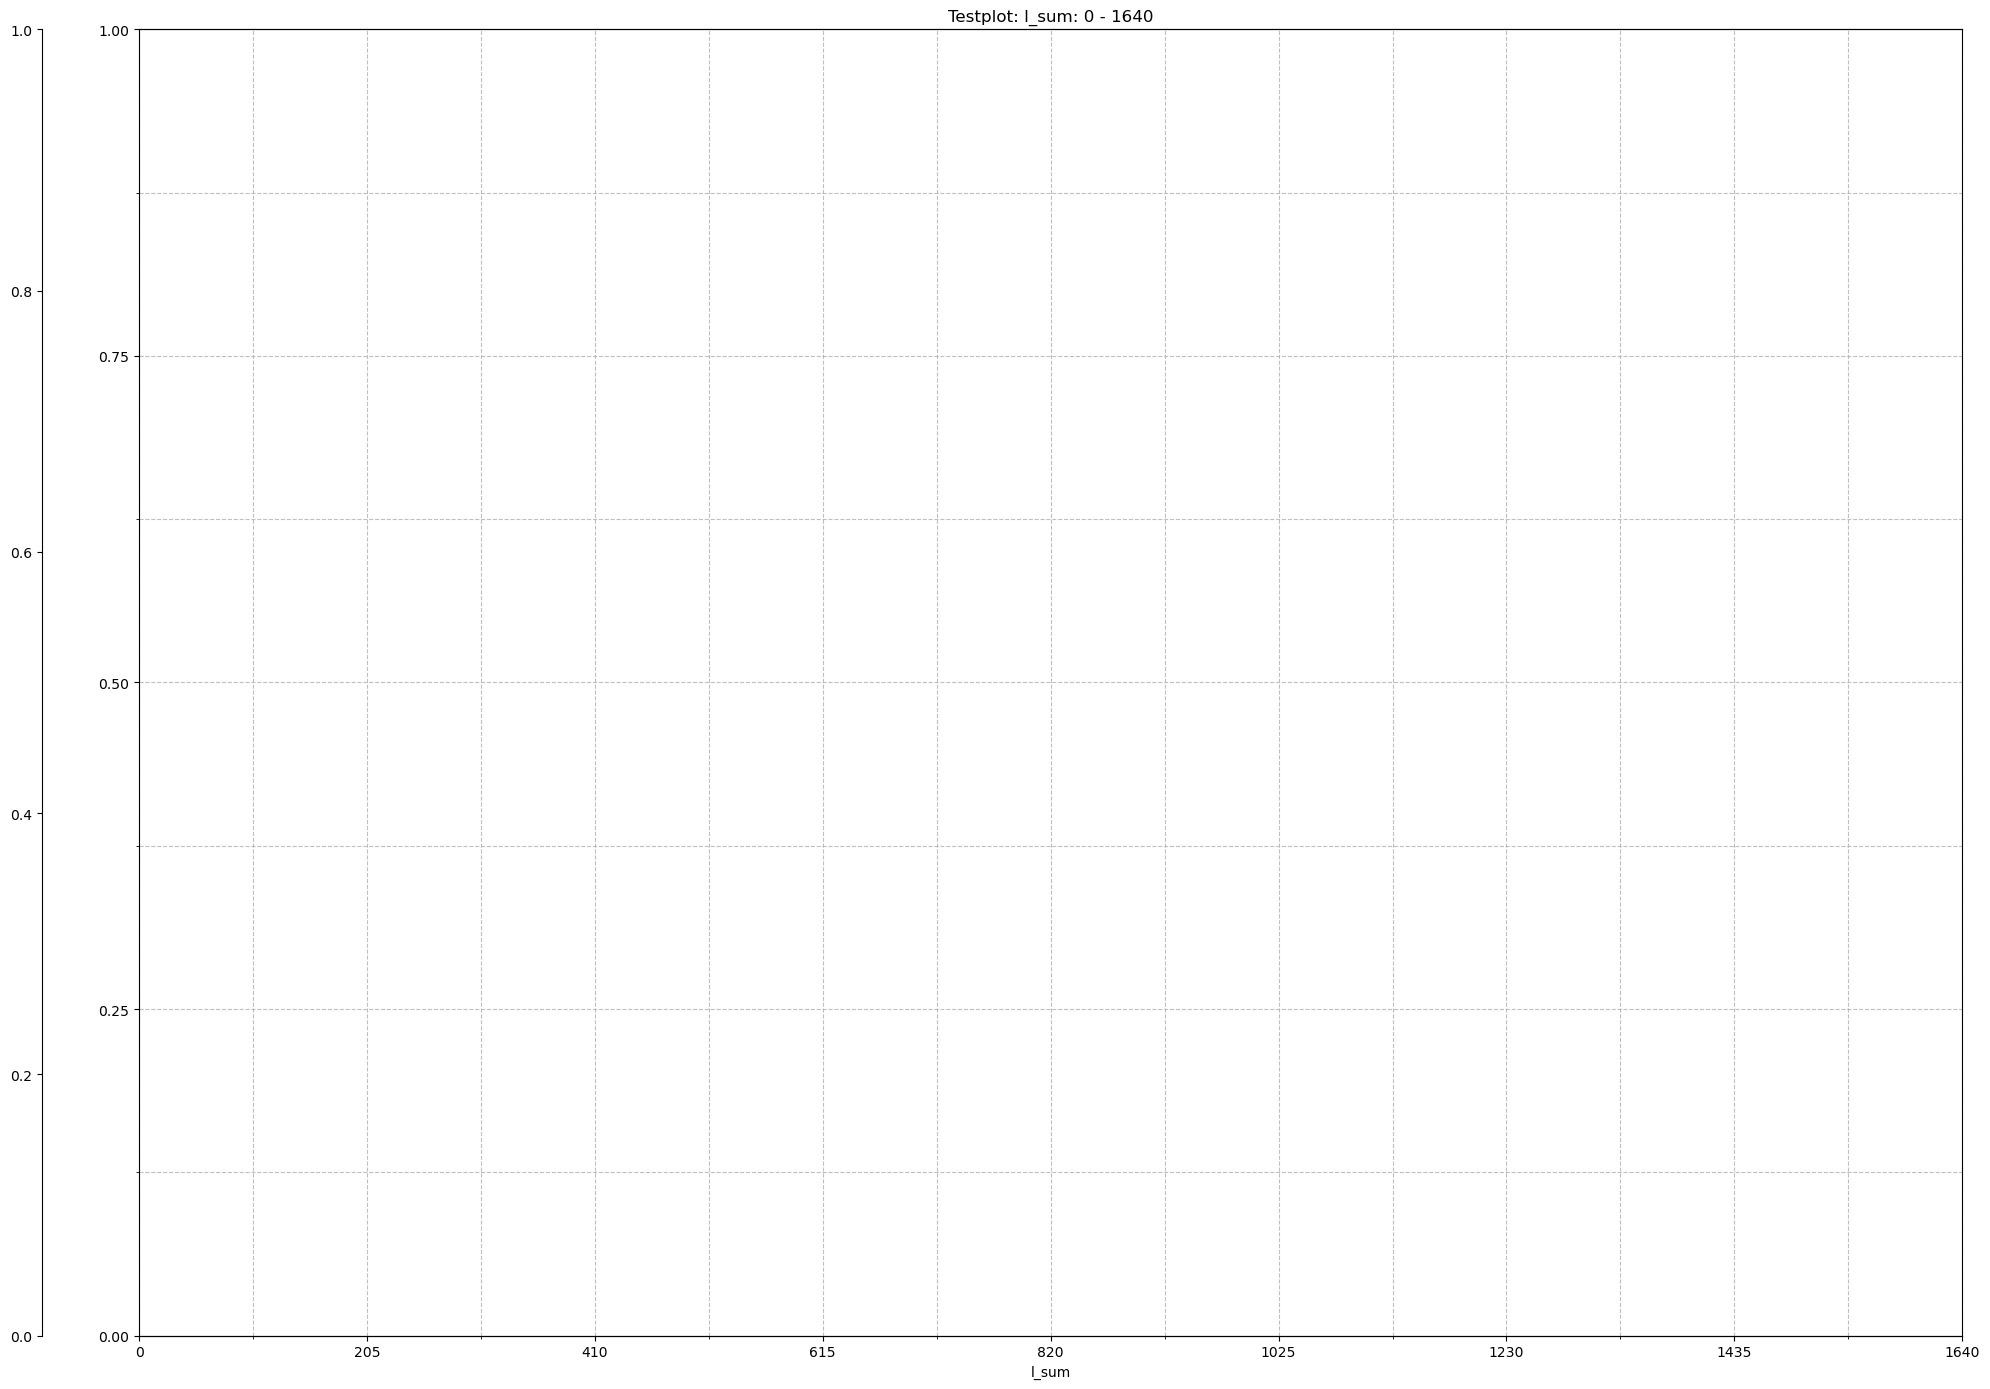

In [17]:
fig, axes, used = plot_time_curves(
    df=df_vec,

    # NEW: interpreted as length window on l_sum (floats), not timestamps
    start=0.0,
    end=1640,  # <-- set this to the l_sum range you want

    properties=["PVEC", "TVEC"],
    axis_labels=["PVEC bar", "TVEC °C"],
    ylims=[(0, 10), (50, 100)],

    # kept for compatibility but not used by the new logic (can be omitted)
    # tks_per_property=...,

    y_label_ticks=[5, 6],
    y_grid_ticks=9,
    x_label_ticks=9,
    x_grid_ticks=17,

    legend=True,
    legend_in_figure=True,
    legend_loc="upper left",
    legend_coords=(0.67, 0.33),
    legend_fontsize=15,

    title_prefix="Testplot: ",
    show_title=True,

    axis_offset=70,
    linestyles=["-", "--", ":"],
    rotate_xticks=0,

    grid=True,
    grid_style="--",
    grid_alpha=0.8,

    missing="warn",
    logger=None,
)


In [18]:
1/0

ZeroDivisionError: division by zero

In [19]:
import matplotlib.pyplot as plt

In [20]:
import pandas as pd

In [21]:
def plot(dfAGSN=pd.DataFrame()
        ,dfAGSNRL=pd.DataFrame()
        ,PHCol='("PVEC", "0")'
        ,mlcCol='mlc_n'
        ,zKoorCol='ZKOR_n'
        ,barBzgCol='H_n'
        ,QMCol='QM'
        ,TCol='T_n'
        ,xCol='LSum'
        
):
                       
    fig, ax0 = plt.subplots(figsize=(20,11.9))
    
    ax0.set_yticks(np.linspace(0, 10, 21))
    ax0.yaxis.set_ticklabels([])
    ax0.grid()

    #PH
    ax1 = ax0.twinx()     
    fyPH(ax1) 
    PH_SL=ax1.plot(dfAGSN[xCol], dfAGSN[PHCol], color='red', label='PH SL',ls='dotted')
    PH_RL=ax1.plot(dfAGSNRL[xCol], dfAGSNRL[PHCol], color='blue', label='PH RL',ls='dotted')
    
    #mlc
    ax11 = ax0.twinx()     
    fymlc(ax11) 
    mlc_SL=ax11.plot(dfAGSN[xCol], dfAGSN[mlcCol], color='red', label='mlc SL')
    mlc_RL=ax11.plot(dfAGSNRL[xCol], dfAGSNRL[mlcCol], color='blue', label='mlc RL')
    
    z=ax11.plot(dfAGSN[xCol], dfAGSN[zKoorCol], color='black', label='z',ls='dashed',alpha=.5)
    
    #barBZG
    ax12 = ax0.twinx()     
    fybarBzg(ax12) 
    barB_SL=ax12.plot(dfAGSN[xCol], dfAGSN[barBzgCol], color='red', label='H SL',ls='dashdot')
    barB_RL=ax12.plot(dfAGSNRL[xCol], dfAGSNRL[barBzgCol], color='blue', label='H RL',ls='dashdot')
    """
    #M
    ax2 = ax0.twinx()     
    fyM(ax2)
    QM_SL=ax2.step(dfAGSN[xCol], dfAGSN[QMCol]*dfAGSN['direction'], color='orange', label='M SL')
    QM_RL=ax2.step(dfAGSNRL[xCol], dfAGSNRL[QMCol]*dfAGSNRL['direction'], color='cyan', label='M RL',ls='--')
    
    #T
    ax3 = ax0.twinx() 
    fyT(ax3)
    T_SL=ax3.plot(dfAGSN[xCol], dfAGSN[TCol], color='pink', label='T SL')
    T_RL=ax3.plot(dfAGSNRL[xCol], dfAGSNRL[TCol], color='lavender', label='T RL')
    """
    ax0.set_title('Longitudinal Section for ')#+dbFilename)

    # added these three lines
    lns =  PH_SL+ PH_RL + mlc_SL+ mlc_RL + barB_SL+ barB_RL#+ QM_SL+ QM_RL + T_SL+ T_RL + z
    labs = [l.get_label() for l in lns]
    ax0.legend(lns, labs)#, loc=0)
    
    plt.show()

In [22]:
def plot(
    dfAGSN=df_vec,
    xCol="l_sum",
    PHCol=("PVEC", 0),
    barBzgCol=("HVEC", 0)
):
    fig, ax0 = plt.subplots(figsize=(20,11.9))
    
    ax0.set_yticks(np.linspace(0, 10, 21))
    ax0.yaxis.set_ticklabels([])
    ax0.grid()

    #PH
    ax1 = ax0.twinx()     
    fyPH(ax1) 
    PH_SL=ax1.plot(dfAGSN[xCol], dfAGSN[PHCol], color='red', label='PH SL',ls='dotted')
    #PH_RL=ax1.plot(dfAGSNRL[xCol], dfAGSNRL[PHCol], color='blue', label='PH RL',ls='dotted')

    #barBZG
    ax12 = ax0.twinx()     
    fybarBzg(ax12) 
    barB_SL=ax12.plot(dfAGSN[xCol], dfAGSN[barBzgCol], color='red', label='H SL',ls='dashdot')
    
    ax0.set_title('Longitudinal Section for ')#+dbFilename)

    # added these three lines
    lns =  PH_SL + barB_SL#+ PH_RL + mlc_SL+ mlc_RL + barB_SL+ barB_RL#+ QM_SL+ QM_RL + T_SL+ T_RL + z
    labs = [l.get_label() for l in lns]
    ax0.legend(lns, labs)#, loc=0)
    
    plt.show()
    

NameError: name 'fyPH' is not defined

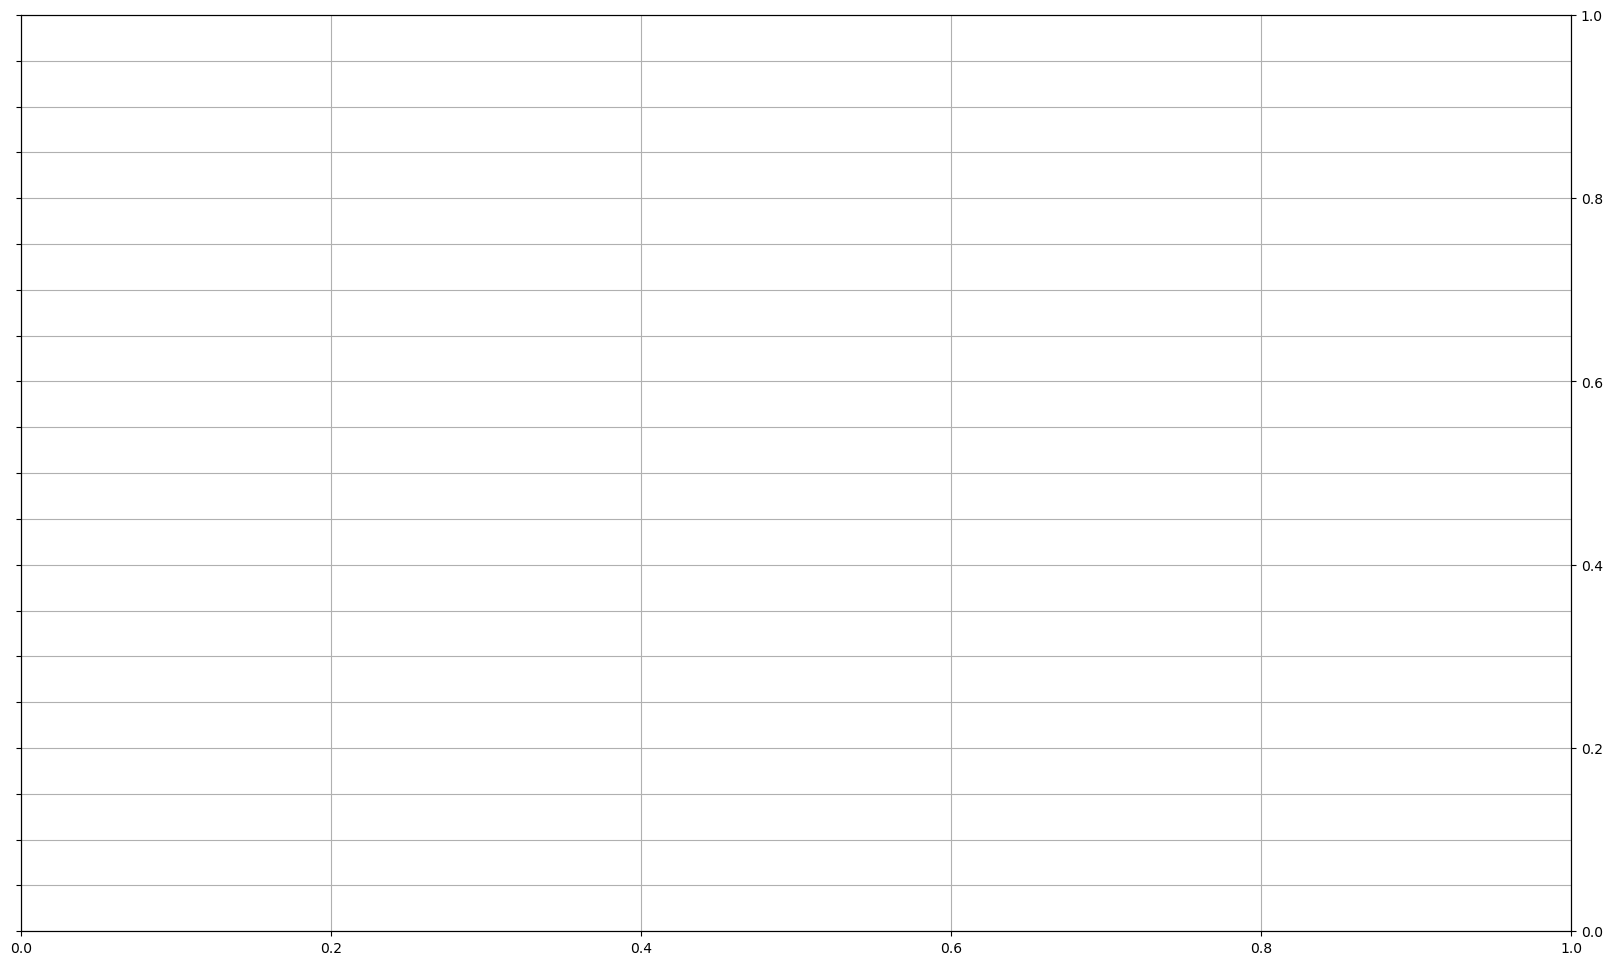

In [23]:
plot(df_vec)

...